# My ScoNet results from RunPod

I could not train on my laptop (RTX 3050, 4 GB), so I trained on a RunPod A40 and downloaded the results as a zip. This notebook is where I open that zip and check what happened, step by step:

1. which runs are in this folder and what files they have
2. the training log: losses and accuracy every 100 iterations
3. the test result that OpenGait printed on RunPod
4. the test accuracy of **every** checkpoint (2k, 4k, ... 20k)
5. a re-check on my laptop, so I can see the confusion matrix and the sensitivity / specificity the paper reports
6. a small `summary.json` per run, which `analysis/compare_with_paper.ipynb` reads

Right now this folder has **ScoNet_MT**, the official OpenGait config (paper Table 4, last row). When I train ScoNet_CE or ScoNet_Triplet, I extract their zips next to it and run this notebook again; every cell loops over all runs it finds.

In [ ]:
from pathlib import Path
import os, re, sys, csv, json, tempfile
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()                         
assert HERE.name == 'result_sconet', f'Open this notebook from reproduce/result_sconet, not {HERE}'
REPRO = HERE.parent                     
MODEL_DIR = REPRO / 'model_sconet'     
DATASET_ROOT = REPRO / 'datasets' / 'Scoliosis1K-sil-pkl'
PARTITION = REPRO / 'datasets' / 'Scoliosis1K_118.json'

LABELS = ['negative', 'neutral', 'positive'] 
MILESTONES = [10000, 14000, 18000]            
LRS = [0.1, 0.01, 0.001, 0.0001]

PAPER = {
    'CNN_CE':         ('CNN',            45.5,  99.0, 27.0),
    'CNN_Triplet':    ('CNN-Triplet',    56.3,  77.0, 85.0),
    'CNN_MT':         ('CNN-MT',         57.8,  96.1, 44.4),
    'ScoNet_CE':      ('ScoNet',         51.3, 100.0, 33.2),
    'ScoNet_Triplet': ('ScoNet-Triplet', 61.2, 100.0, 46.6),
    'ScoNet_MT':      ('ScoNet-MT',      82.0,  99.0, 76.5),
}
CONFIG_OF = {'ScoNet_MT': 'sconet_mt.yaml', 'ScoNet_Triplet': 'sconet_triplet.yaml', 'ScoNet_CE': 'sconet.yaml'}

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})


def show_table(rows, cols, fmt=None):
    fmt = fmt or {}
    cells = [[(fmt.get(c, '{}').format(r.get(c, '')) if r.get(c, '') != '' else '') for c in cols] for r in rows]
    width = [max(len(c), *(len(x[i]) for x in cells)) if cells else len(c) for i, c in enumerate(cols)]
    print('  '.join(c.ljust(w) for c, w in zip(cols, width)))
    print('  '.join('-' * w for w in width))
    for x in cells:
        print('  '.join(v.ljust(w) for v, w in zip(x, width)))


def find_runs():
    runs = []
    for d in sorted(p for p in HERE.iterdir() if p.is_dir()):
        hits = sorted((d / 'output').glob('*/*/*/logs')) if (d / 'output').is_dir() else []
        if hits:
            runs.append({'name': d.name, 'dir': d, 'opengait_dir': hits[0].parent,
                         'config': CONFIG_OF.get(d.name)})
    return runs


RUNS = find_runs()
print('Runs found:', [r['name'] for r in RUNS] or 'none yet')


Runs found: ['ScoNet_MT']


## 1. Which runs are here

In [2]:
for run in RUNS:
    print(f"== {run['name']}  (trained with configs/{run['config']})")
    for p in sorted(run['dir'].rglob('*')):
        if p.is_file():
            print(f"   {p.relative_to(run['dir'])}   {p.stat().st_size / 1e6:8.2f} MB")


== ScoNet_MT  (trained with configs/sconet_mt.yaml)
   checkpoint_sweep_runpod.csv       0.00 MB
   local_check\iter_02000.npz       0.09 MB
   local_check\iter_04000.npz       0.08 MB
   local_check\iter_06000.npz       0.09 MB
   local_check\iter_08000.npz       0.08 MB
   local_check\iter_10000.npz       0.08 MB
   local_check\iter_12000.npz       0.08 MB
   local_check\iter_14000.npz       0.08 MB
   local_check\iter_16000.npz       0.08 MB
   local_check\iter_18000.npz       0.08 MB
   local_check\iter_20000.npz       0.08 MB
   output\Scoliosis1K\ScoNet\ScoNet\checkpoints\ScoNet-02000.pt      56.22 MB
   output\Scoliosis1K\ScoNet\ScoNet\checkpoints\ScoNet-04000.pt      56.22 MB
   output\Scoliosis1K\ScoNet\ScoNet\checkpoints\ScoNet-06000.pt      56.22 MB
   output\Scoliosis1K\ScoNet\ScoNet\checkpoints\ScoNet-08000.pt      56.22 MB
   output\Scoliosis1K\ScoNet\ScoNet\checkpoints\ScoNet-10000.pt      56.22 MB
   output\Scoliosis1K\ScoNet\ScoNet\checkpoints\ScoNet-12000.pt      56.2

## 2. The training log

OpenGait writes one line every 100 iterations. Each number is the **average over those 100 iterations**:

| column | what it means to me |
|---|---|
| `softmax_loss` | cross-entropy on the 3 classes (label smoothing 0.1, so it can never reach 0; the minimum is about 0.29) |
| `softmax_accuracy` | how many (clip, strip) pairs in the batch got the right class. It is per strip and per **training** batch, not the test score |
| `triplet_loss` | average of the triplets that still break the 0.2 margin (zero ones are left out) |
| `triplet_hard_loss` | the worst triplet in the batch |
| `triplet_loss_num` | how many triplets still break the margin. When this falls, the triplet task is nearly solved |
| `triplet_mean_dist` | average distance between the clips' embeddings |
| `cost_s` | seconds for those 100 iterations |

CE-only runs have no triplet columns.

In [ ]:
TRAIN_LINE = re.compile(r'Iteration (\d+), Cost ([\d.]+)s, (.*)')


def read_training_log(run):
    rows = []
    for f in sorted((run['opengait_dir'] / 'logs').glob('*.txt')):
        for line in f.read_text(errors='ignore').splitlines():
            m = TRAIN_LINE.search(line)
            if m:
                row = {'iteration': int(m[1]), 'cost_s': float(m[2])}
                for pair in m[3].split(', '):
                    key, value = pair.split('=')
                    row[key] = float(value)
                rows.append(row)
    return rows


for run in RUNS:
    run['train'] = read_training_log(run)
    rows = run['train']
    print(f"\n== {run['name']}: {len(rows)} log lines, last iteration {rows[-1]['iteration'] if rows else '-'}")
    if not rows:
        continue
    cols = [c for c in ['iteration', 'softmax_loss', 'softmax_accuracy', 'triplet_loss', 'triplet_hard_loss',
                        'triplet_loss_num', 'triplet_mean_dist', 'cost_s'] if c in rows[0]]
    picks = [r for r in rows if r['iteration'] in (100, 200) or r['iteration'] % 2000 == 0]
    show_table(picks, cols, {c: '{:.4f}' for c in cols if c not in ('iteration',)})
    total_h = sum(r['cost_s'] for r in rows) / 3600
    print(f"training time from the log: {total_h:.2f} h")
    bad = [r['iteration'] for r in rows if any(np.isnan(v) for k, v in r.items() if k != 'iteration')]
    print('lines with NaN:', bad[:10] if bad else 'none')



== ScoNet_MT: 200 log lines, last iteration 20000
iteration  softmax_loss  softmax_accuracy  triplet_loss  triplet_hard_loss  triplet_loss_num  triplet_mean_dist  cost_s 
---------  ------------  ----------------  ------------  -----------------  ----------------  -----------------  -------
100        1.2196        0.5407            0.4964        2.6260             3104.4319         2.8494             52.8100
200        0.8079        0.7263            0.2661        1.3275             1390.5557         2.4822             49.3500
2000       0.6562        0.8139            0.1916        0.6510             111.0256          6.0503             48.7800
4000       0.6202        0.8398            0.1743        0.5378             66.5969           6.7189             48.9900
6000       0.6893        0.7888            0.1716        0.5325             57.6244           7.3320             48.9000
8000       0.6414        0.8143            0.1475        0.4334             42.6075           7.6649  

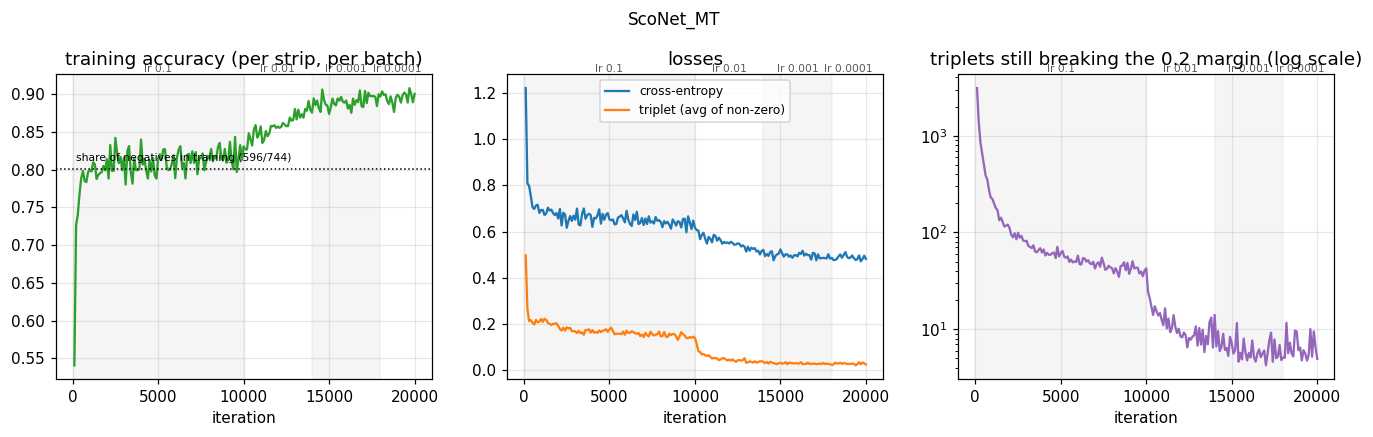

In [4]:
def shade_lr(ax, top=None):
    edges = [0] + MILESTONES + [20000]
    for i, (a, b) in enumerate(zip(edges[:-1], edges[1:])):
        ax.axvspan(a, b, color='0.5', alpha=0.08 if i % 2 == 0 else 0.0)
        ax.text((a + b) / 2, 1.0, f'lr {LRS[i]:g}', transform=ax.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=7, color='0.35')


for run in RUNS:
    rows = run['train']
    if not rows:
        continue
    it = np.array([r['iteration'] for r in rows])
    has_triplet = 'triplet_loss' in rows[0]
    fig, axes = plt.subplots(1, 3 if has_triplet else 2, figsize=(15 if has_triplet else 10, 3.6))
    ax = axes[0]
    ax.plot(it, [r['softmax_accuracy'] for r in rows], color='tab:green')
    ax.axhline(596 / 744, ls=':', color='k', lw=1)
    ax.text(200, 596 / 744 + 0.01, 'share of negatives in training (596/744)', fontsize=7)
    ax.set_title('training accuracy (per strip, per batch)'); ax.set_xlabel('iteration'); shade_lr(ax)
    ax = axes[1]
    ax.plot(it, [r['softmax_loss'] for r in rows], label='cross-entropy')
    if has_triplet:
        ax.plot(it, [r['triplet_loss'] for r in rows], label='triplet (avg of non-zero)')
    ax.set_title('losses'); ax.set_xlabel('iteration'); ax.legend(fontsize=8); shade_lr(ax)
    if has_triplet:
        ax = axes[2]
        ax.semilogy(it, [r['triplet_loss_num'] for r in rows], color='tab:purple')
        ax.set_title('triplets still breaking the 0.2 margin (log scale)'); ax.set_xlabel('iteration'); shade_lr(ax)
    fig.suptitle(run['name'], y=1.04, fontsize=11)
    plt.show()


**What I see in ScoNet_MT.**

- For the first 10,000 iterations (lr 0.1) the training accuracy sits around **0.80**. That is almost exactly the share of negative children in training: 596 of 744 = 0.80. So the model was mostly answering "negative" for everyone, the easiest guess on this split.
- Right after the learning rate drops to 0.01 at iteration 10,000, the triplet loss falls fast and the accuracy climbs past 0.85 for the first time. The smaller steps let it learn finer differences than "mostly negative".
- After 14,000 almost nothing changes. The drops to 0.001 and 0.0001 only polish.
- `triplet_loss_num` goes from about 3,100 to about 5. In ScoNet-MT the positive is another clip of the **same child**, so this task becomes almost solved and the triplet loss stops pushing much later in training.
- The whole run took about 2.7 hours on one A40.

## 3. What OpenGait printed at test time

These are the lines `evaluate_scoliosis` wrote to the log: accuracy, and **macro** precision, recall and F1. Macro means the three classes count equally, however many children each class has. A log file only appears here when the test ran with `--log_to_file`.

In [ ]:
def read_test_logs(run):
    found = {}
    for f in sorted((run['opengait_dir'] / 'logs').glob('*.txt')):
        text = f.read_text(errors='ignore')
        if 'Total Accuracy' not in text:
            continue
        ckpt = re.search(r'Restore Parameters from .*-(\d+)\.pt', text)
        row = {'log': f.name, 'iteration': int(ckpt[1]) if ckpt else None}
        for key, label in [('accuracy', 'Total Accuracy'), ('macro_precision', 'Macro-avg Precision'),
                           ('macro_recall', 'Macro-avg Recall'), ('macro_f1', 'Macro-avg F1 Score')]:
            row[key] = float(re.search(label + r': ([\d.]+)%', text)[1])
        found[row['iteration']] = row       
    return [found[k] for k in sorted(found)]


for run in RUNS:
    run['tests'] = read_test_logs(run)
    print(f"\n== {run['name']}")
    show_table(run['tests'], ['iteration', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'log'])



== ScoNet_MT
iteration  accuracy  macro_precision  macro_recall  macro_f1  log                    
---------  --------  ---------------  ------------  --------  -----------------------
20000      76.77     83.01            70.25         68.75     2026-10-28-16-00-33.txt


My first test try (15:43) has no result: it stopped with *"The batch size (8) must be equal to the number of GPUs (1)"*. I changed the test batch size to 1 and ran it again (15:45). The 16:00 log is the same 20k checkpoint tested once more, and it gives exactly the same numbers, which tells me the test is deterministic.

## 4. Every checkpoint

A checkpoint was saved every 2,000 iterations. Here is the test accuracy of each one.

- For new runs, `runpod.py sweep` tests every checkpoint with `--log_to_file`, so the numbers come from the log files.
- For ScoNet_MT, my sweep loop on RunPod printed to the terminal only, so I copied those numbers into `checkpoint_sweep_runpod.csv`. Section 5 recomputes them on my laptop to confirm I copied them right.


== ScoNet_MT
iteration  accuracy  macro_recall
---------  --------  ------------
2000       27.24     33.33       
4000       28.97     35.85       
6000       35.51     46.93       
8000       27.24     33.33       
10000      28.57     35.24       
12000      82.38     80.79       
14000      64.09     60.29       
16000      82.64     75.53       
18000      78.64     71.18       
20000      76.77     70.25       


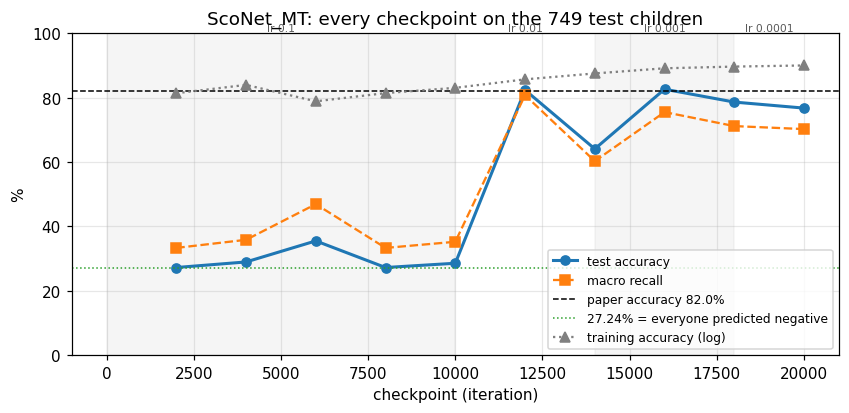

In [ ]:
def checkpoint_sweep(run):
    rows = [r for r in run['tests'] if r['iteration']]
    csv_path = run['dir'] / 'checkpoint_sweep_runpod.csv'
    if len(rows) < 3 and csv_path.exists():
        with open(csv_path) as f:
            rows = [{'iteration': int(r['iteration']), 'accuracy': float(r['accuracy']),
                     'macro_recall': float(r['macro_recall']), 'source': r['source']} for r in csv.DictReader(f)]
    return sorted(rows, key=lambda r: r['iteration'])


for run in RUNS:
    run['sweep'] = checkpoint_sweep(run)
    print(f"\n== {run['name']}")
    show_table(run['sweep'], ['iteration', 'accuracy', 'macro_recall'])

for run in RUNS:
    if not run['sweep']:
        continue
    it = [r['iteration'] for r in run['sweep']]
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(it, [r['accuracy'] for r in run['sweep']], 'o-', lw=2, label='test accuracy')
    ax.plot(it, [r['macro_recall'] for r in run['sweep']], 's--', label='macro recall')
    if run['name'] in PAPER:
        ax.axhline(PAPER[run['name']][1], color='k', ls='--', lw=1, label=f"paper accuracy {PAPER[run['name']][1]}%")
    ax.axhline(100 * 204 / 749, color='tab:green', ls=':', lw=1, label='27.24% = everyone predicted negative')
    if run['train']:
        tr = {r['iteration']: 100 * r['softmax_accuracy'] for r in run['train']}
        ax.plot(it, [tr.get(i, np.nan) for i in it], '^:', color='0.5', label='training accuracy (log)')
    shade_lr(ax)
    ax.set_ylim(0, 100); ax.set_xlabel('checkpoint (iteration)'); ax.set_ylabel('%')
    ax.set_title(f"{run['name']}: every checkpoint on the 749 test children"); ax.legend(fontsize=8, loc='lower right')
    plt.show()


**What I see in ScoNet_MT.**

- **2k to 10k (lr 0.1): 27 to 36%.** 27.24% is exactly 204 / 749, the share of negative children in the test set. So at 2k and 8k the model predicted *negative* for **every** child, the same "mostly negative" behaviour as in the training log. Macro recall 33.33% says the same: 100% recall on negative, 0% on the other two, divided by 3.
- **12k: 82.38%.** One learning-rate drop later it jumps by 54 points. This is where the real learning happens.
- **12k to 20k: 64 to 83%.** It moves around a lot between checkpoints. The test set is 56% positive, and positive and neutral sit close together, so a small shift in that boundary moves dozens of children at once (one child = 0.13%).
- **After 16k** the training accuracy keeps rising (0.89 → 0.90) while the test accuracy falls (82.6 → 78.6 → 76.8). I read this as the model memorising the 744 training children.
- My run did reach the paper's **82.0%** (82.38% at 12k, 82.64% at 16k), but the final checkpoint, which the config tests by default, gave **76.77%**.

## 5. Re-checking on my laptop: confusion matrix, sensitivity and specificity

OpenGait only prints accuracy and macro precision / recall / F1. The paper reports **sensitivity** and **specificity**, and I want to see *which* children are confused with which. For that I need each child's prediction, which OpenGait does not save.

So here I rebuild the exact model from `model_sconet/` on my laptop, load each checkpoint, and run the 749 test children again. It is the same code path as `--phase test`: all frames, float16, mean of the logits over the strips, then argmax. The logits are cached in `local_check/`, so this only runs once.

In [ ]:
RUN_LOCAL_CHECK = True  

_models = {}


def build_test_model(config_name):
    if config_name in _models:
        return _models[config_name]
    import torch
    import torch.distributed as dist
    code = str(MODEL_DIR / 'opengait')
    if code not in sys.path:
        sys.path.insert(0, code)
    if not dist.is_initialized():
        store = Path(tempfile.gettempdir()) / f'opengait_store_{os.getpid()}'
        store.unlink(missing_ok=True)
        dist.init_process_group('gloo', init_method=store.as_uri(), rank=0, world_size=1)
    from utils import config_loader, get_msg_mgr
    from modeling import models
    old = os.getcwd()
    os.chdir(MODEL_DIR)                     
    try:
        cfgs = config_loader(f'configs/{config_name}')
    finally:
        os.chdir(old)
    cfgs['data_cfg']['dataset_root'] = str(DATASET_ROOT)
    cfgs['data_cfg']['dataset_partition'] = str(PARTITION)
    cfgs['data_cfg']['num_workers'] = 0     
    cfgs['data_cfg']['cache'] = False
    cfgs['evaluator_cfg']['restore_hint'] = 0 # I load each checkpoint myself
    get_msg_mgr().init_logger(str(Path(tempfile.gettempdir()) / 'opengait_notebook'), False)
    model = getattr(models, cfgs['model_cfg']['model'])(cfgs, training=False)
    _models[config_name] = model
    return model


def checkpoint_logits(run, iteration):
    cache = run['dir'] / 'local_check' / f'iter_{iteration:05d}.npz'
    if cache.exists():
        d = np.load(cache)
        return d['logits'], d['true']
    if not RUN_LOCAL_CHECK:
        return None, None
    import torch
    ckpt = next((run['opengait_dir'] / 'checkpoints').glob(f'*-{iteration:05d}.pt'))
    model = build_test_model(run['config'])
    model.load_state_dict(torch.load(ckpt, map_location='cuda:0', weights_only=False)['model'])
    model.eval()
    with torch.no_grad():
        info = model.inference(0)
    logits = np.asarray(info['embeddings'], dtype=np.float32)
    true = np.array([LABELS.index(t) for t in model.test_loader.dataset.types_list])
    cache.parent.mkdir(exist_ok=True)
    np.savez_compressed(cache, logits=logits, true=true,
                        subject=np.array(model.test_loader.dataset.label_list))
    return logits, true


def scores(true, pred):
    cm = np.zeros((3, 3), int)
    for t, p in zip(true, pred):
        cm[t, p] += 1
    support, predicted, correct = cm.sum(1), cm.sum(0), np.diag(cm)
    recall = np.divide(correct, support, out=np.zeros(3), where=support > 0)
    precision = np.divide(correct, predicted, out=np.zeros(3), where=predicted > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(3), where=(precision + recall) > 0)
    return {'cm': cm, 'accuracy': 100 * correct.sum() / cm.sum(),
            'macro_precision': 100 * precision.mean(), 'macro_recall': 100 * recall.mean(), 'macro_f1': 100 * f1.mean(),
            'recall': 100 * recall, 'precision': 100 * precision,
            'sensitivity': 100 * recall[2], 'specificity': 100 * recall[0]}


for run in RUNS:
    its = sorted(int(p.stem[-5:]) for p in (run['opengait_dir'] / 'checkpoints').glob('*.pt'))
    run['local'] = {}
    for it in its:
        logits, true = checkpoint_logits(run, it)
        if logits is not None:
            run['local'][it] = scores(true, logits.mean(-1).argmax(-1))   # same rule as evaluate_scoliosis
    print(f"\n== {run['name']}: checked {len(run['local'])} of {len(its)} checkpoints on this computer")
    show_table([dict(iteration=it, **{k: v for k, v in s.items() if np.ndim(v) == 0}) for it, s in run['local'].items()],
               ['iteration', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'sensitivity', 'specificity'],
               {k: '{:.2f}' for k in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'sensitivity', 'specificity']})



== ScoNet_MT: checked 10 of 10 checkpoints on this computer
iteration  accuracy  macro_precision  macro_recall  macro_f1  sensitivity  specificity
---------  --------  ---------------  ------------  --------  -----------  -----------
2000       27.24     9.08             33.33         14.27     0.00         100.00     
4000       28.97     66.85            35.85         19.19     1.19         100.00     
6000       35.51     54.47            46.93         31.18     4.53         96.57      
8000       27.24     9.08             33.33         14.27     0.00         100.00     
10000      28.57     53.23            35.24         18.01     0.95         100.00     
12000      82.24     79.79            80.63         78.92     80.91        95.10      
14000      64.09     79.58            60.29         56.64     59.43        100.00     
16000      82.64     85.09            75.53         75.26     87.59        98.53      
18000      78.64     84.39            71.18         69.81     82.58  

First I check that my laptop and RunPod agree. If they do, I can trust the confusion matrices below.

In [ ]:
for run in RUNS:
    print(f"== {run['name']}")
    for t in run['tests'] + [r for r in run['sweep'] if r.get('source')]:
        mine = run['local'].get(t['iteration'])
        if mine is None:
            continue
        for key in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']:
            if key in t:
                diff = abs(mine[key] - t[key])
                print(f"   iter {t['iteration']:5d} {key:16s} RunPod {t[key]:6.2f}  laptop {mine[key]:6.2f}  "
                      f"{'same' if diff < 0.01 else 'DIFFERENT by %.2f' % diff}")


== ScoNet_MT
   iter 20000 accuracy         RunPod  76.77  laptop  76.77  same
   iter 20000 macro_precision  RunPod  83.01  laptop  83.01  same
   iter 20000 macro_recall     RunPod  70.25  laptop  70.25  same
   iter 20000 macro_f1         RunPod  68.75  laptop  68.75  same
   iter  2000 accuracy         RunPod  27.24  laptop  27.24  same
   iter  2000 macro_recall     RunPod  33.33  laptop  33.33  same
   iter  4000 accuracy         RunPod  28.97  laptop  28.97  same
   iter  4000 macro_recall     RunPod  35.85  laptop  35.85  same
   iter  6000 accuracy         RunPod  35.51  laptop  35.51  same
   iter  6000 macro_recall     RunPod  46.93  laptop  46.93  same
   iter  8000 accuracy         RunPod  27.24  laptop  27.24  same
   iter  8000 macro_recall     RunPod  33.33  laptop  33.33  same
   iter 10000 accuracy         RunPod  28.57  laptop  28.57  same
   iter 10000 macro_recall     RunPod  35.24  laptop  35.24  same
   iter 12000 accuracy         RunPod  82.38  laptop  82.24  DI

### Confusion matrices

Rows are the true class, columns the predicted class. Each cell shows the number of children and the share of that row. I show the **final** checkpoint (the honest result, chosen without looking at the test set) and, if different, the checkpoint that happened to score **best on the test set** (optimistic, because the test set picked it).

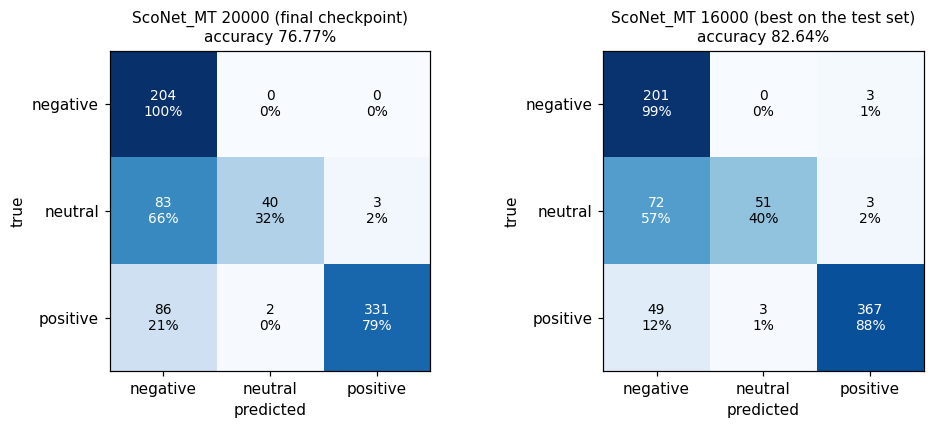

In [9]:
def plot_confusion(ax, cm, title):
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            share = cm[i, j] / cm[i].sum()
            ax.text(j, i, f'{cm[i, j]}\n{share:.0%}', ha='center', va='center',
                    color='white' if share > 0.5 else 'black', fontsize=9)
    ax.set_xticks(range(3), LABELS); ax.set_yticks(range(3), LABELS)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title, fontsize=10); ax.grid(False)


for run in RUNS:
    if not run['local']:
        print(run['name'], ': no local check yet')
        continue
    final = max(run['local'])
    best = max(run['local'], key=lambda i: run['local'][i]['accuracy'])
    run['final_it'], run['best_it'] = final, best
    picks = [final] if best == final else [final, best]
    fig, axes = plt.subplots(1, len(picks), figsize=(4.6 * len(picks), 4))
    axes = np.atleast_1d(axes)
    for ax, it in zip(axes, picks):
        s = run['local'][it]
        tag = 'final checkpoint' if it == final else 'best on the test set'
        plot_confusion(ax, s['cm'], f"{run['name']} {it} ({tag})\naccuracy {s['accuracy']:.2f}%")
    plt.tight_layout(); plt.show()


### Sensitivity and specificity, compared with the paper

The paper defines them as:
- **sensitivity** = "true positives (actual scoliosis cases correctly classified) out of all positive cases"
- **specificity** = "true negatives (actual normal cases correctly classified) out of all negative cases"

It does not say how the **neutral** class is counted in these two numbers. My reading, which I use below: sensitivity = recall of the *positive* class, specificity = recall of the *negative* class. I also show neutral recall separately, because neither of the paper's two numbers covers it. So the sensitivity / specificity comparison depends on my reading; the accuracy comparison does not.

In [10]:
rows = []
for run in RUNS:
    if not run['local']:
        continue
    paper = PAPER.get(run['name'])
    if paper:
        rows.append({'what': f"paper {paper[0]}", 'accuracy': paper[1], 'sensitivity': paper[2], 'specificity': paper[3]})
    for it, tag in [(run['final_it'], 'final'), (run['best_it'], 'best on test')]:
        s = run['local'][it]
        rows.append({'what': f"mine {run['name']} {it} ({tag})", 'accuracy': s['accuracy'],
                     'sensitivity': s['sensitivity'], 'specificity': s['specificity'],
                     'neutral recall': s['recall'][1], 'macro_f1': s['macro_f1']})
show_table(rows, ['what', 'accuracy', 'sensitivity', 'specificity', 'neutral recall', 'macro_f1'],
           {k: '{:.1f}' for k in ['accuracy', 'sensitivity', 'specificity', 'neutral recall', 'macro_f1']})


what                                 accuracy  sensitivity  specificity  neutral recall  macro_f1
-----------------------------------  --------  -----------  -----------  --------------  --------
paper ScoNet-MT                      82.0      99.0         76.5                                 
mine ScoNet_MT 20000 (final)         76.8      79.0         100.0        31.7            68.7    
mine ScoNet_MT 16000 (best on test)  82.6      87.6         98.5         40.5            75.3    


**What I see in ScoNet_MT.**

- **My laptop agrees with RunPod** on 9 of the 10 checkpoints, digit for digit. At 12k it differs by one child (82.24% here vs 82.38% on RunPod). For that child the top two class scores differ by only about 0.00006, so the tiny float16 rounding difference between the A40 and my RTX 3050 flips it. Everything else matches, so I trust the confusion matrices.
- **Final checkpoint (20k):** all 204 negative children are right. But 83 of the 126 neutral children and 86 of the 419 positive children are also called *negative*. Almost every mistake is "negative", the class that makes up 80% of the training data.
- **That is why my sensitivity is 79.0 and my specificity is 100.0.** The paper reports the opposite pattern: sensitivity 99.0, specificity 76.5. With my reading of the definitions, the paper's model almost never misses a positive child but calls about a quarter of the negative children positive. Mine never calls a negative child positive but misses about one in five positives. At 16k my accuracy is the same as the paper's (82.6 vs 82.0), yet the mistakes are very different.
- I cannot tell from the paper why. The reasons I can think of: the paper may count the neutral class differently in these two numbers; the paper's checkpoint may come from a different point of the same unstable curve; or its run simply ended in a different place. The accuracy comparison is solid; the sensitivity / specificity comparison is only as good as my reading of the definitions.
- **Neutral is the hardest class:** recall 31.7% at 20k and 40.5% at 16k. Only 74 neutral children are in training, and neutral sits between the other two classes.

### Each strip on its own

ScoNet gives every one of the 16 horizontal strips its own classifier, and `evaluate_scoliosis` averages their logits before `argmax`. The cached logits in `local_check/` keep all 16 strips (shape `[749, 3, 16]`), so I can also score each strip **by itself**: `argmax` on that strip's 3 logits only. This shows which height of the body the trained model actually relies on.

Strip 1 is the top of the feature map (head) and strip 16 the bottom (feet). Each strip is one row of the 16 x 11 feature map, about 4 pixel rows of the 64-pixel silhouette, and neighbouring strips see overlapping areas, so the body part for each strip is only approximate.

These numbers are computed on the **test set after training**. They describe what the model learned; they must not be used to pick strips.


== ScoNet_MT 16000 (best on test): all 16 strips averaged = 82.64%
strip  accuracy  negative  neutral  positive
-----  --------  --------  -------  --------
1      70.49     93.14     7.94     78.28   
2      74.90     90.20     15.08    85.44   
3      74.50     86.27     11.11    87.83   
4      77.57     94.61     25.40    84.96   
5      76.77     94.61     38.10    79.71   
6      80.77     91.18     37.30    88.78   
7      82.38     88.24     48.41    89.74   
8      80.37     87.25     46.83    87.11   
9      76.90     91.18     50.79    77.80   
10     78.10     93.63     56.35    77.09   
11     72.63     90.69     54.76    69.21   
12     76.37     89.71     50.00    77.80   
13     62.88     96.57     47.62    51.07   
14     59.81     88.24     69.84    42.96   
15     41.79     86.76     77.78    9.07    
16     43.79     90.20     65.08    14.80   

== ScoNet_MT 20000 (final): all 16 strips averaged = 76.77%
strip  accuracy  negative  neutral  positive
-----  -------- 

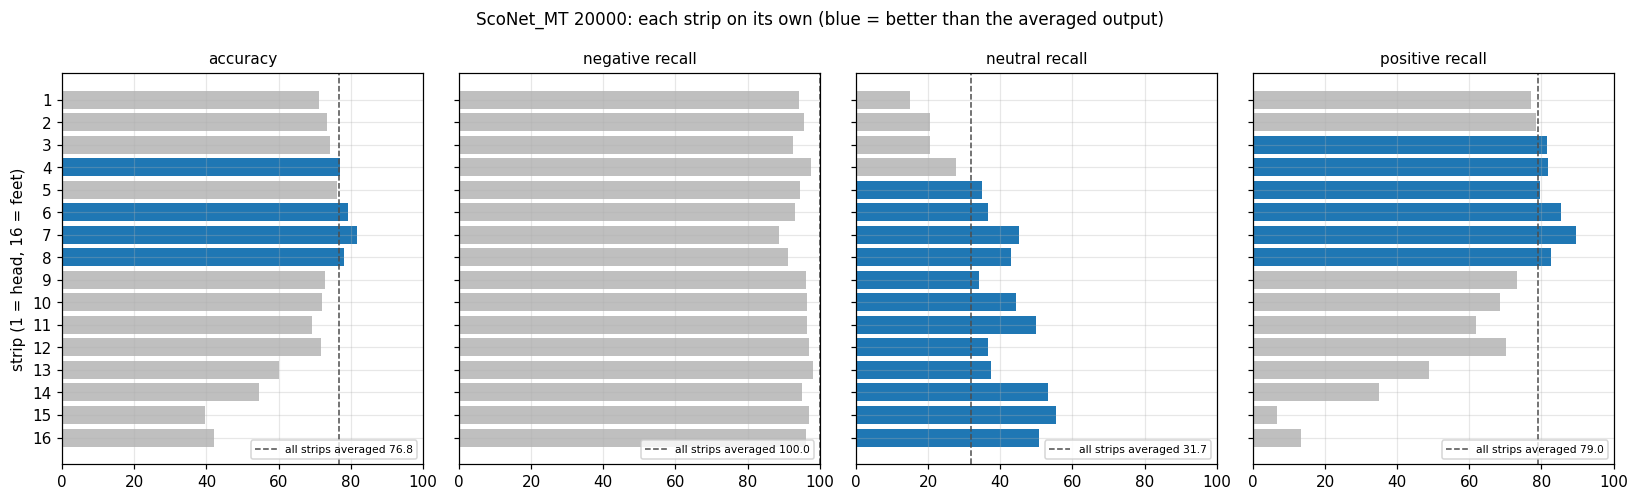

   all 16 strips accuracy  76.77   recall negative 100.00  neutral  31.75  positive  79.00
   strips 1-14   accuracy  79.04   recall negative  99.51  neutral  30.16  positive  83.77
   strips 1-12   accuracy  78.37   recall negative  98.53  neutral  27.78  positive  83.77


In [ ]:
def strip_scores(logits, true):
    return [scores(true, logits[:, :, s].argmax(-1)) for s in range(logits.shape[-1])]


for run in RUNS:
    if not run['local']:
        continue
    for it in sorted({run['final_it'], run['best_it']}):
        logits, true = checkpoint_logits(run, it)
        run.setdefault('strips', {})[it] = strip_scores(logits, true)
        tag = 'final' if it == run['final_it'] else 'best on test'
        print(f"\n== {run['name']} {it} ({tag}): all {logits.shape[-1]} strips averaged = {run['local'][it]['accuracy']:.2f}%")
        show_table([{'strip': s + 1, 'accuracy': r['accuracy'], 'negative': r['recall'][0],
                     'neutral': r['recall'][1], 'positive': r['recall'][2]} for s, r in enumerate(run['strips'][it])],
                   ['strip', 'accuracy', 'negative', 'neutral', 'positive'],
                   {k: '{:.2f}' for k in ['accuracy', 'negative', 'neutral', 'positive']})

for run in RUNS:
    if not run.get('strips'):
        continue
    it = run['final_it']
    per_strip, avg = run['strips'][it], run['local'][it]
    panels = [('accuracy', [r['accuracy'] for r in per_strip], avg['accuracy'])] + \
             [(f'{c} recall', [r['recall'][i] for r in per_strip], avg['recall'][i]) for i, c in enumerate(LABELS)]
    strips = np.arange(1, len(per_strip) + 1)
    fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), sharey=True)
    for ax, (name, values, ref) in zip(axes, panels):
        ax.barh(strips, values, color=['C0' if v > ref else '0.75' for v in values])
        ax.axvline(ref, color='0.3', ls='--', lw=1, label=f'all strips averaged {ref:.1f}')
        ax.set_xlim(0, 100); ax.set_title(name, fontsize=10); ax.legend(fontsize=7, loc='lower right')
    axes[0].invert_yaxis(); axes[0].set_yticks(strips); axes[0].set_ylabel('strip (1 = head, 16 = feet)')
    fig.suptitle(f"{run['name']} {it}: each strip on its own (blue = better than the averaged output)", fontsize=11)
    plt.tight_layout(); plt.show()

    # what happens to the averaged output without the feet strips (indicative only: chosen on the test set)
    logits, true = checkpoint_logits(run, it)
    for name, keep in [('all 16 strips', slice(0, 16)), ('strips 1-14', slice(0, 14)), ('strips 1-12', slice(0, 12))]:
        s = scores(true, logits[:, :, keep].mean(-1).argmax(-1))
        print(f"   {name:13s} accuracy {s['accuracy']:6.2f}   recall negative {s['recall'][0]:6.2f}  "
              f"neutral {s['recall'][1]:6.2f}  positive {s['recall'][2]:6.2f}")

### The strips on the body

To see which part of the body each strip covers, I average the silhouettes of test children of each class (all frames, same 64 x 44 cut as BaseSilCuttingTransform) and draw the 16 strips on top. Each band is coloured by that strip's recall for that class at the final checkpoint: green = the strip finds this class well, red = it misses it.

Strip s sits on input rows 4(s-1) to 4s-1, because ResNet9 shrinks the 64 rows to 16 (two stride-2 layers). The network sees a wider area than its own 4 rows, so the colour marks where a strip is centred, not a hard border.

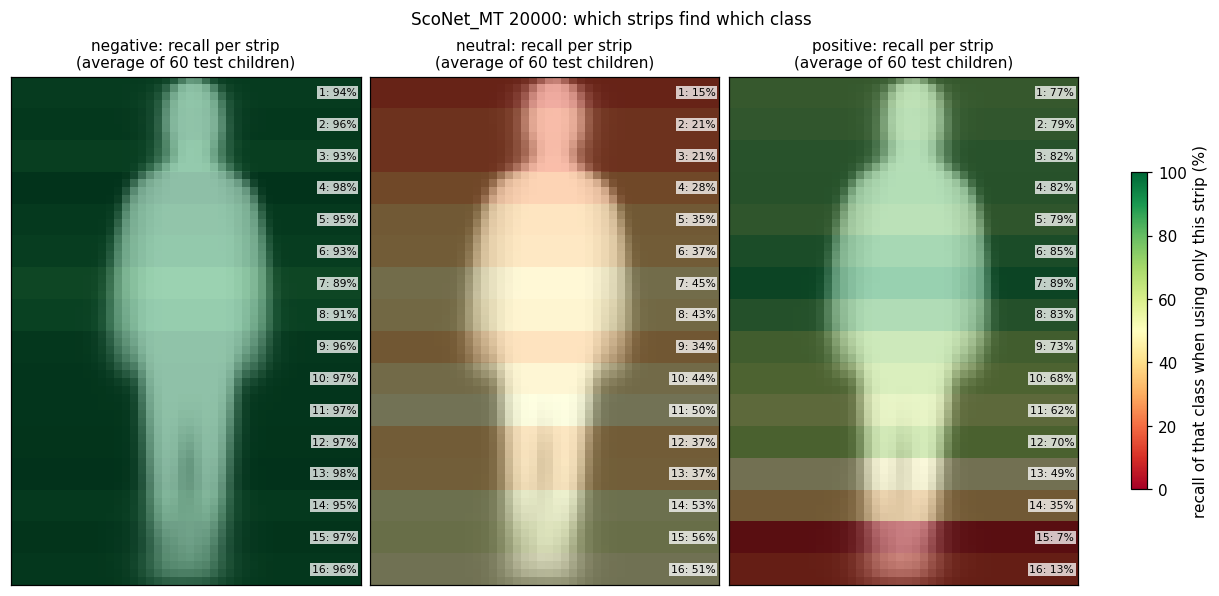

In [ ]:
import pickle


def mean_silhouette(subjects, cls, limit=60):
    frames = []
    for sid in subjects[:limit]:
        with open(DATASET_ROOT / sid / cls / '000_180' / '000_180.pkl', 'rb') as f:
            seq = pickle.load(f)
        frames.append(seq[..., 10:-10].mean(0) / 255.0)   # same 64 x 44 cut as BaseSilCuttingTransform
    return np.mean(frames, 0)


for run in RUNS:
    if not run.get('strips'):
        continue
    it = run['final_it']
    cache = np.load(run['dir'] / 'local_check' / f'iter_{it:05d}.npz')
    subject, true = cache['subject'], cache['true']
    cmap = plt.get_cmap('RdYlGn')
    fig, axes = plt.subplots(1, 3, figsize=(11, 5.4), layout='constrained')
    for ci, (ax, cls) in enumerate(zip(axes, LABELS)):
        ids = sorted(str(s) for s in subject[true == ci])
        ax.imshow(mean_silhouette(ids, cls), cmap='gray', vmin=0, vmax=1)
        for s, r in enumerate(run['strips'][it]):
            rec = r['recall'][ci]
            ax.axhspan(4 * s - 0.5, 4 * s + 3.5, color=cmap(rec / 100), alpha=0.45, lw=0)
            ax.text(43, 4 * s + 1.5, f'{s + 1}: {rec:.0f}%', ha='right', va='center', fontsize=7,
                    bbox=dict(fc='white', alpha=0.75, lw=0, pad=1))
        ax.set_xlim(-0.5, 43.5); ax.set_ylim(63.5, -0.5)
        ax.set_title(f'{cls}: recall per strip\n(average of {min(len(ids), 60)} test children)', fontsize=10)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 100)), ax=axes, shrink=0.6,
                 label='recall of that class when using only this strip (%)')
    fig.suptitle(f"{run['name']} {it}: which strips find which class", fontsize=11)
    plt.show()

**What I see in ScoNet_MT (20k).**

- **The middle of the body is the most useful.** Strips 6 to 8 are the best single strips, and strip 7 on its own scores 81.84%, higher than the averaged output (76.77%).
- **The feet strips almost never find positive children.** Positive recall is 6.7% for strip 15 and 13.4% for strip 16, but they still count as much as every other strip in the average.
- **Neutral is the opposite.** Neutral recall is highest in the lower strips (50.8 to 55.6% for strips 14 to 16), against 31.7% for the averaged output.
- Dropping strips 15 and 16 from the average raises accuracy to 79.04%, but neutral recall falls to 30.2%. No single set of strips is best for every class, and since I chose those strips by looking at the test set, this is only a hint, not a result.

## 6. Summary for the analysis notebook

In [11]:
def as_plain(s):
    return {k: (v.tolist() if isinstance(v, np.ndarray) else float(v)) for k, v in s.items()}


for run in RUNS:
    summary = {'run': run['name'], 'family': 'sconet', 'config': run['config'],
               'paper': dict(zip(['name', 'accuracy', 'sensitivity', 'specificity'], PAPER[run['name']])) if run['name'] in PAPER else None,
               'training_hours': sum(r['cost_s'] for r in run['train']) / 3600 if run['train'] else None,
               'sweep': run['sweep'],
               'final': dict(iteration=run.get('final_it'), **as_plain(run['local'][run['final_it']])) if run['local'] else None,
               'best_on_test': dict(iteration=run.get('best_it'), **as_plain(run['local'][run['best_it']])) if run['local'] else None}
    out = run['dir'] / 'summary.json'
    out.write_text(json.dumps(summary, indent=2))
    print('wrote', out.relative_to(REPRO))


wrote result_sconet\ScoNet_MT\summary.json


## 7. What I conclude about ScoNet-MT

- I trained the official config with the official code. The only change that touches how it runs is the test batch size (8 → 1 for one GPU), and that does not change any prediction.
- **The paper's 82.0% accuracy is reached during my run:** 82.38% at 12k and 82.64% at 16k.
- **The final checkpoint gives 76.77%.** Between 12k and 20k the test accuracy moves between 64% and 83%, so one number from one checkpoint of one run can be several points off in either direction.
- My honest headline is **76.77% (final checkpoint)**, with **82.64%** as the best checkpoint. I mark the best one as optimistic, because I picked it by looking at the test set.
- All the learning happened after the first learning-rate drop at 10k. Before that, the model called almost every child "negative".
- My model's mistakes are almost all "negative". The paper's sensitivity / specificity suggest the opposite trade-off, which I cannot explain from the paper alone.
- This is one run with one seed. I have not measured how much a second run would differ.